# Data analysis: drift periods P1 to P4

Checks that the four periods differ in language style, and measures data quality
issues before training. Run `dvc pull` (or `dvc repro`) first.

IDSA and the slang lexicon have no stated license, so this notebook shows only
counts, charts, and word frequencies, never full tweets.

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PERIODS = ["p1", "p2", "p3", "p4"]
SPLITS = ["train", "val", "test"]
LABELS = ["negative", "neutral", "positive"]
LABEL_COLORS = {"negative": "#2a78d6", "neutral": "#eb6834", "positive": "#1baf7a"}
SERIES_COLOR = "#2a78d6"

periods_dir = Path("../data/periods")
frames = [
    pd.read_csv(
        periods_dir / period / f"{split}.tsv",
        sep="\t",
        quoting=3,  # csv.QUOTE_NONE: quotes are part of the text
        keep_default_na=False,
    ).assign(period=period, split=split)
    for period in PERIODS
    for split in SPLITS
]
df = pd.concat(frames, ignore_index=True)
df["words"] = df["text"].str.split()
df["n_words"] = df["words"].str.len()
len(df)

21798

## 1. Size and label mix

In [2]:
pd.crosstab(df["period"], df["split"], margins=True)[SPLITS + ["All"]]

split,train,val,test,All
period,,,,
p1,8871,1901,1901,12673
p2,2129,456,457,3042
p3,2129,456,457,3042
p4,2128,456,457,3041
All,15257,3269,3272,21798


In [3]:
label_share = pd.crosstab(df["period"], df["label"], normalize="index")[LABELS]
label_share.round(3)

label,negative,neutral,positive
period,,,
p1,0.316,0.107,0.577
p2,0.256,0.497,0.247
p3,0.256,0.497,0.247
p4,0.256,0.497,0.247


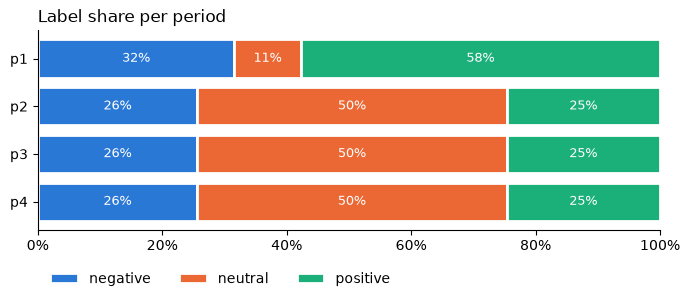

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
left = pd.Series(0.0, index=label_share.index)
for label in LABELS:
    share = label_share[label]
    ax.barh(
        label_share.index,
        share,
        left=left,
        color=LABEL_COLORS[label],
        label=label,
        edgecolor="white",
        linewidth=2,
    )
    for period, value in share.items():
        ax.text(
            left[period] + value / 2,
            period,
            f"{value:.0%}",
            ha="center",
            va="center",
            color="white",
            fontsize=9,
        )
    left += share
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Label share per period", loc="left")
ax.legend(ncols=3, loc="upper left", bbox_to_anchor=(0, -0.15), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 2. Text length (words per text)

In [5]:
df.groupby("period")["n_words"].describe()[["mean", "25%", "50%", "75%", "max"]]

,mean,25%,50%,75%,max
period,,,,,
p1,29.083090,14.0,25.0,42.0,96.0
p2,13.235043,8.0,14.0,18.0,28.0
p3,13.347469,8.0,15.0,18.0,27.0
p4,13.049655,8.0,14.0,18.0,28.0


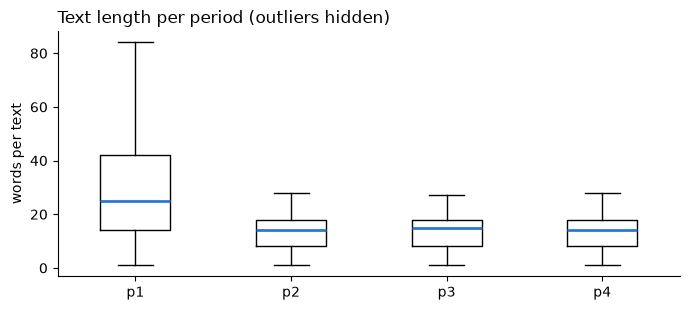

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.boxplot(
    [df.loc[df["period"] == p, "n_words"] for p in PERIODS],
    tick_labels=PERIODS,
    showfliers=False,
    medianprops={"color": SERIES_COLOR, "linewidth": 2},
)
ax.set_ylabel("words per text")
ax.set_title("Text length per period (outliers hidden)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 3. Vocabulary drift

Out-of-vocabulary (OOV) rate: the share of word occurrences in a period's test set
that never appear in a reference training set. A higher rate means the model meets
more words it has never seen.

In [7]:
def vocab(period, split="train"):
    rows = df[(df["period"] == period) & (df["split"] == split)]
    return {w for words in rows["words"] for w in words}


def oov_rate(period, reference_vocab):
    test_words = [
        w
        for words in df.loc[(df["period"] == period) & (df["split"] == "test"), "words"]
        for w in words
    ]
    return sum(w not in reference_vocab for w in test_words) / len(test_words)


p1_vocab, p2_vocab = vocab("p1"), vocab("p2")
oov = pd.DataFrame(
    {
        "vs P1 train": [oov_rate(p, p1_vocab) for p in PERIODS],
        "vs P2 train": [oov_rate(p, p2_vocab) for p in PERIODS],
    },
    index=PERIODS,
)
oov.round(3)

,vs P1 train,vs P2 train
p1,0.032,0.203
p2,0.260,0.213
p3,0.370,0.301
p4,0.638,0.606


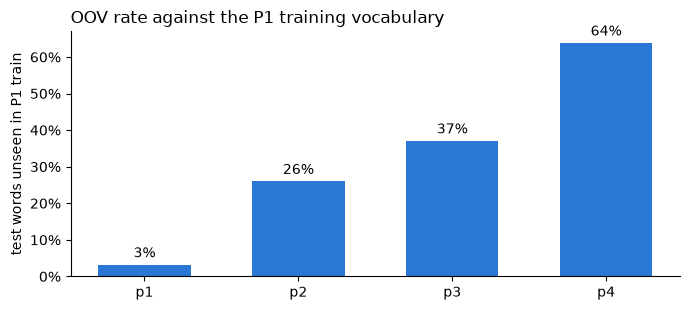

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar(PERIODS, oov["vs P1 train"], color=SERIES_COLOR, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in oov["vs P1 train"]], padding=3)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_ylabel("test words unseen in P1 train")
ax.set_title("OOV rate against the P1 training vocabulary", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 4. Most frequent words per period

In [9]:
top_words = pd.DataFrame(
    {
        p: [
            w
            for w, _ in Counter(
                w for words in df.loc[df["period"] == p, "words"] for w in words
            ).most_common(15)
        ]
        for p in PERIODS
    }
)
top_words.index += 1
top_words

,p1,p2,p3,p4
1,nya,aku,aku,uka
2,yang,kamu,kamu,umak
3,dan,dan,yg,nad
4,di,yang,kita,atik
5,tidak,kita,dan,gnay
6,saya,di,yang,yg
7,dengan,yg,di,uti
8,enak,ini,ini,gnaro
9,ini,ada,ada,aid
10,makanan,apa,dn,uam


## 5. Data quality checks after cleaning

Rough word-list checks on P2, which holds the IDSA tweets without any rewrite. They are
estimates, not a language detector. The cleaning step already drops tweets with a Malay
marker word and removes `amp` and punctuation, so these counts show what is left over.

- **Malay:** at least one word that is common in Malay but rare in Indonesian. The list
  here still has `macam`, which cleaning keeps because it is also Indonesian.
- **English:** at least half the words are common English words (texts with 3+ words).
- **`amp`:** a leftover of the HTML code `&amp;` in the raw tweets.

In [10]:
# Same words as the cleaning step plus "macam", so the result is what cleaning left behind.
MALAY_WORDS = {"nak", "macam", "sikit", "awak", "korang", "cuba", "faham", "tengok", "kat"}
ENGLISH_WORDS = {
    "the",
    "and",
    "to",
    "of",
    "is",
    "you",
    "i",
    "a",
    "in",
    "it",
    "that",
    "for",
    "my",
    "me",
    "on",
    "this",
    "be",
    "are",
    "with",
    "so",
    "not",
    "but",
    "have",
    "just",
    "your",
    "was",
    "we",
    "all",
    "do",
    "what",
    "when",
    "can",
    "if",
    "like",
    "love",
    "people",
}

p2 = df[df["period"] == "p2"]
is_malay = p2["words"].map(lambda ws: bool(MALAY_WORDS & set(ws)))
is_english = p2["words"].map(
    lambda ws: len(ws) >= 3 and sum(w in ENGLISH_WORDS for w in ws) / len(ws) >= 0.5
)
has_amp = df["words"].map(lambda ws: "amp" in ws)

pd.DataFrame(
    {
        "texts": [is_malay.sum(), is_english.sum(), has_amp.sum()],
        "share of P2": [is_malay.mean(), is_english.mean(), None],
    },
    index=["Malay (P2)", "English (P2)", "contains amp (all periods)"],
).round(3)

,texts,share of P2
Malay (P2),31,0.01
English (P2),1,0.00
contains amp (all periods),0,NaN


In [11]:
# Label mix of the flagged P2 tweets, to see whether they skew one class.
pd.DataFrame(
    {
        "Malay": p2.loc[is_malay, "label"].value_counts(normalize=True),
        "English": p2.loc[is_english, "label"].value_counts(normalize=True),
        "all P2": p2["label"].value_counts(normalize=True),
    }
).reindex(LABELS).round(3)

,Malay,English,all P2
label,,,
negative,0.226,NaN,0.256
neutral,0.516,1.0,0.497
positive,0.258,NaN,0.247


## 6. Summary

**Drift is clear and grows every period.** The share of test words never seen in P1
training rises from 3% (P1) to 26% (P2), 37% (P3), and 64% (P4). This is the
vocabulary change the continual-learning setup needs.

**Other differences between P1 and the IDSA periods:**

- **Label mix:** neutral is 11% of P1 but 50% of P2 to P4 (label shift). Macro-F1
  weighs each class equally, but results should report this shift next to the score.
- **Length:** P1 texts have a median of 25 words, IDSA tweets 14 to 15. IDSA tweets never
  go above 28 words, and many end mid-word, so they look cut off at collection time.
- **Punctuation:** removed from every dataset in cleaning, so the top P1 tokens are now
  words. A model can no longer tell P1 from later periods by punctuation alone.

**Cleaning rules applied before the split:**

- **Malay tweets:** IDSA tweets with a marker word (`nak`, `sikit`, `awak`, `korang`,
  `cuba`, `faham`, `tengok`, `kat`) are dropped. After this, 31 P2 tweets (1%) still
  contain `macam`, which is also Indonesian, so they stay. This is a word-list filter,
  not language detection, so it can also drop a few Indonesian tweets.
- **`amp`:** the leftover of `&amp;` is removed. No text contains it now.
- **Label mix of IDSA:** unchanged by the Malay filter (negative 26.2% before, 25.6% after).

**Other notes:** English tweets are almost absent (1 tweet). The frequent P4 token `nad`
is the word `dan` written in reverse, not English.